# English → French Machine Translation on *Pride and Prejudice*
### Transformer vs mT5 (encoder–decoder) vs LLaMA vs Gemma (decoder-only)
Foundations of Generative AI (ICT4403), Assignment 3

**Task.** Translate English sentences from Jane Austen's *Pride and Prejudice* into French, using the sentence-aligned English–French edition of the novel in the OPUS Books corpus.

| # | Model | Architecture | Size used | How it is adapted |
|---|---|---|---|---|
| 1 | Basic Transformer | encoder–decoder | ~10M params | trained **from scratch** on our training split |
| 2 | mT5 (`google/mt5-small`) | encoder–decoder | ~300M | **full fine-tuning** |
| 3 | LLaMA (`meta-llama/Llama-3.2-1B-Instruct`) | decoder-only | ~1.2B | **few-shot prompting** (3 examples) and **LoRA fine-tuning** |
| 4 | Gemma (`google/gemma-3-1b-it`) | decoder-only | ~1.0B | **few-shot prompting** (3 examples) and **LoRA fine-tuning** |

**Comparable settings.** All systems use the same train / validation / test split, translate the same test sentences, use greedy decoding (no beam search), the same maximum output length (128 tokens), the same inference batch size (16), and run on the same GPU.

**Before running (Colab):**
1. *Runtime → Change runtime type → T4 GPU*.
2. LLaMA and Gemma are gated models. Log in to huggingface.co and click **"Agree / Request access"** on both model pages: https://huggingface.co/meta-llama/Llama-3.2-1B-Instruct and https://huggingface.co/google/gemma-3-1b-it.
3. Create a **Read** token at https://huggingface.co/settings/tokens. In Colab, open the 🔑 *Secrets* panel on the left, add a secret named `HF_TOKEN` with the token as its value, and switch on *Notebook access*.
4. *Runtime → Run all*. The full run takes roughly 1–1.5 hours on a T4. Each finished model is saved to `results/systems/`, so if Colab disconnects, re-running skips the models that are already done.

## 1. Setup

In [ ]:
# Colab already has torch, transformers, datasets, accelerate and tokenizers.
!pip install -q sacrebleu peft sentencepiece

In [ ]:
import os, re, gc, json, math, time, random, shutil, unicodedata, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import transformers, sacrebleu, peft
from packaging import version
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM,
                          get_linear_schedule_with_warmup)
from peft import LoraConfig, get_peft_model

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only"
# bfloat16 only on GPUs that support it natively (A100 / L4 / H100). A T4 runs everything in float32.
USE_BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__,
      "| sacrebleu", sacrebleu.__version__)
print("Device:", DEVICE, "|", GPU_NAME, "| bf16:", USE_BF16)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Select Runtime -> Change runtime type -> T4 GPU, otherwise this will take many hours.")

torch 2.11.0+cu130 | transformers 5.20.2 | peft 0.21.2 | sacrebleu 2.6.0
Device: cuda | Tesla T4 | bf16: False


In [ ]:
# ------------------------------- configuration -------------------------------
SEED = 42
SRC_LANG, TGT_LANG = "en", "fr"

# data
MIN_WORDS, MAX_WORDS = 3, 60         # keep English sentences with 3-60 words
VAL_FRAC, TEST_FRAC = 0.10, 0.10
VAL_MAX, TEST_MAX = 500, 500

# shared inference settings (identical for every system)
INFER_BS = 16
MAX_NEW_TOKENS = 128
TEMPERATURES = [0.0, 0.7, 1.0, 1.3]  # 0.0 = greedy
TEMP_SUBSET = 100                     # test sentences used for the temperature study

# 1) basic Transformer, trained from scratch
TF_VOCAB, TF_D_MODEL, TF_HEADS, TF_LAYERS, TF_FF, TF_DROPOUT = 8000, 256, 4, 3, 1024, 0.1
TF_EPOCHS, TF_BS, TF_LR, TF_PATIENCE, TF_MAX_LEN = 40, 64, 5e-4, 5, 128

# 2) mT5, full fine-tuning
MT5_ID = "google/mt5-small"
MT5_PREFIX = "translate English to French: "
MT5_EPOCHS, MT5_BS, MT5_LR, MT5_PATIENCE, MT5_MAX_LEN = 10, 16, 5e-4, 3, 128

# 3) + 4) decoder-only LLMs: few-shot prompting and LoRA fine-tuning
LLAMA_ID = "meta-llama/Llama-3.2-1B-Instruct"
GEMMA_ID = "google/gemma-3-1b-it"
N_SHOTS = 3
LLM_EPOCHS, LLM_BS, LLM_ACCUM, LLM_LR, LLM_MAX_LEN = 1, 4, 4, 2e-4, 256
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]

RESUME = True    # skip a system whose results file already exists
DATA_DIR, RESULTS_DIR = "data", "results"
SYS_DIR, PLOTS_DIR = f"{RESULTS_DIR}/systems", f"{RESULTS_DIR}/plots"
for d in (DATA_DIR, RESULTS_DIR, SYS_DIR, PLOTS_DIR):
    os.makedirs(d, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

In [ ]:
# Hugging Face login, needed for the gated LLaMA and Gemma weights
from huggingface_hub import login
HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_token")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN:
    login(token=HF_TOKEN)
    print("Logged in to Hugging Face.")
else:
    print("No HF_TOKEN found. Add it in Colab Secrets (see the top of the notebook); LLaMA and Gemma will fail without it.")

Logged in to Hugging Face.


## 2. Dataset: *Pride and Prejudice*, English–French (OPUS Books)
**Source:** OPUS Books corpus (Tiedemann, 2012), English–French part, built from public-domain novels whose translations are aligned sentence by sentence.
- Hugging Face: https://huggingface.co/datasets/Helsinki-NLP/opus_books (config `en-fr`)
- OPUS: https://opus.nlpl.eu/Books/corpus/version/Books

The `en-fr` set contains several novels stored one after another. *Pride and Prejudice* is cut out by locating its first sentence (*"It is a truth universally acknowledged…"*) and its last sentence (*"…had been the means of uniting them."*). The extracted pairs are saved to `data/pride_prejudice_en_fr.csv`, so later runs reuse exactly the same data.

In [ ]:
DATA_CSV = f"{DATA_DIR}/pride_prejudice_en_fr.csv"
START_KEY, END_KEY = "truth universally acknowledged", "means of uniting them"

def extract_novel(rows, start_key=START_KEY, end_key=END_KEY):
    # rows: list of (en, fr) in corpus order -> slice from the novel's first to its last sentence, or None
    start = next((i for i, (en, _) in enumerate(rows) if start_key in en.lower()), None)
    if start is None:
        return None
    end = next((j for j in range(start, len(rows)) if end_key in rows[j][0].lower()), None)
    return rows[start:(end + 1 if end is not None else len(rows))]

if os.path.exists(DATA_CSV):
    pairs_raw = pd.read_csv(DATA_CSV, keep_default_na=False)
    DATA_SOURCE = "cached file " + DATA_CSV
else:
    from datasets import load_dataset
    ds = load_dataset("Helsinki-NLP/opus_books", "en-fr", split="train")
    records = sorted(ds.to_list(), key=lambda r: int(r["id"]))      # corpus order
    rows = [(r["translation"]["en"], r["translation"]["fr"]) for r in records]
    print(f"Full OPUS Books en-fr: {len(rows):,} sentence pairs")
    novel = extract_novel(rows)
    if novel is None or len(novel) < 1000:
        print("WARNING: Pride and Prejudice was not found in OPUS Books en-fr. Falling back to a random "
              "6,000-pair sample of the whole en-fr corpus. Mention this in the README.")
        rng = np.random.default_rng(SEED)
        novel = [rows[i] for i in rng.choice(len(rows), size=min(6000, len(rows)), replace=False)]
        DATA_SOURCE = "OPUS Books en-fr (random sample, fallback)"
    else:
        DATA_SOURCE = "OPUS Books en-fr, Pride and Prejudice"
    pairs_raw = pd.DataFrame(novel, columns=["en", "fr"])
    pairs_raw.to_csv(DATA_CSV, index=False)

print(DATA_SOURCE, "->", len(pairs_raw), "aligned pairs")
print("First pair:", tuple(pairs_raw.iloc[0]))
print("Last pair: ", tuple(pairs_raw.iloc[-1]))

README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-fr/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

en-fr/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/127085 [00:00<?, ? examples/s]

Full OPUS Books en-fr: 127,085 sentence pairs
OPUS Books en-fr, Pride and Prejudice -> 4903 aligned pairs
First pair: ('It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife. However little known the feelings or views of such a man may be on his first entering a neighbourhood, this truth is so well fixed in the minds of the surrounding families, that he is considered the rightful property of some one or other of their daughters.', 'C’est une vérité universellement reconnue qu’un célibataire pourvu d’une belle fortune doit avoir envie de se marier, et, si peu que l’on sache de son sentiment a cet égard, lorsqu’il arrive dans une nouvelle résidence, cette idée est si bien fixée dans l’esprit de ses voisins qu’ils le considerent sur-le-champ comme la propriété légitime de l’une ou l’autre de leurs filles.')
Last pair:  ('Darcy, as well as Elizabeth, really loved them; and they were both ever sensible of the warmest gratitude t

### Preprocessing
1. Unicode NFC normalisation, typographic apostrophes → `'`, whitespace collapsed.
2. Remove empty lines, chapter headings and exact duplicate pairs.
3. Keep pairs whose English side has 3–60 words and whose French/English length ratio lies between 0.5 and 2.5. This removes misaligned pairs, where one side is much longer than the other.
4. Shuffle with a fixed seed and split into train / validation / test (80 / 10 / 10, with validation and test capped at 500 sentences).

Text is **not** lower-cased and punctuation is kept, because BLEU and chrF are computed on the natural, detokenised French.

In [ ]:
def normalise(s):
    s = unicodedata.normalize("NFC", str(s))
    s = s.replace("’", "'").replace("‘", "'").replace(" ", " ")
    return re.sub(r"\s+", " ", s).strip()

df = pairs_raw.copy()
df["en"], df["fr"] = df["en"].map(normalise), df["fr"].map(normalise)
n0 = len(df)
df = df[(df.en != "") & (df.fr != "")]
df = df[~df.en.str.match(r"(?i)^chapter\s+[0-9ivxlc]+\.?$")]
df = df.drop_duplicates()
df["en_words"], df["fr_words"] = df.en.str.split().str.len(), df.fr.str.split().str.len()
df = df[(df.en_words >= MIN_WORDS) & (df.en_words <= MAX_WORDS)]
ratio = df.fr_words / df.en_words
df = df[(ratio >= 0.5) & (ratio <= 2.5)].reset_index(drop=True)
print(f"{n0:,} raw pairs -> {len(df):,} after cleaning")

idx = np.random.default_rng(SEED).permutation(len(df))
n_test = min(int(TEST_FRAC * len(df)), TEST_MAX)
n_val = min(int(VAL_FRAC * len(df)), VAL_MAX)
test_df = df.iloc[idx[:n_test]].reset_index(drop=True)
val_df = df.iloc[idx[n_test:n_test + n_val]].reset_index(drop=True)
train_df = df.iloc[idx[n_test + n_val:]].reset_index(drop=True)
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part[["en", "fr"]].to_csv(f"{DATA_DIR}/{name}.csv", index=False)
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")

TRAIN_SRC, TRAIN_TGT = train_df.en.tolist(), train_df.fr.tolist()
VAL_SRC, VAL_TGT = val_df.en.tolist(), val_df.fr.tolist()
TEST_SRC, TEST_TGT = test_df.en.tolist(), test_df.fr.tolist()

4,903 raw pairs -> 4,358 after cleaning
train 3,488 | val 435 | test 435


,value
source,"OPUS Books en-fr, Pride and Prejudice"
raw_pairs,4903
clean_pairs,4358
train,3488
val,435
test,435
mean_en_words,21.8
mean_fr_words,20.9
en_vocab,5702
fr_vocab,7833


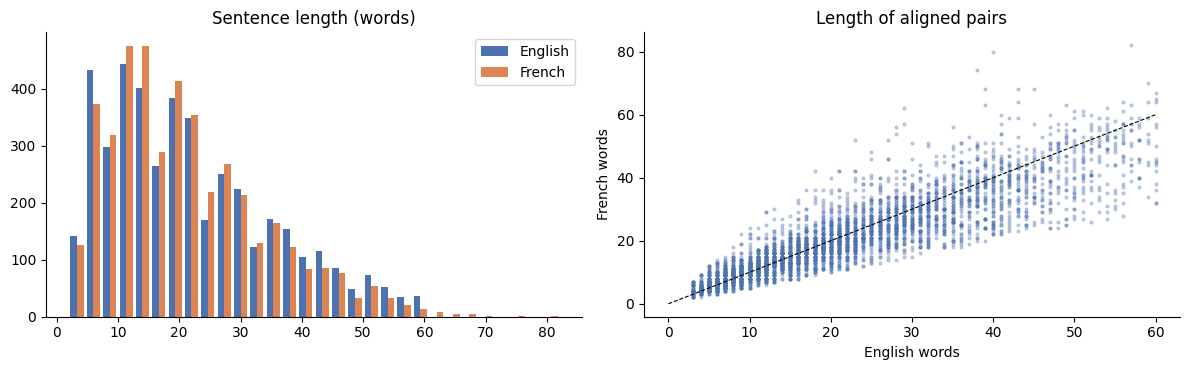

,en,fr
0,"""I should take him, even on _my_ slight acquai...","– D'apres le peu que je connais de lui, il me ..."
1,It is very often nothing but our own vanity th...,Bien souvent c'est votre propre vanité qui vou...
2,"Will you be very angry with me, my dear Lizzy,...","M'en voudrez-vous beaucoup, ma chere Lizzy, si..."
3,"Elizabeth listened with delight to the happy, ...",Elizabeth se réjouit d'entendre sa sour lui ex...
4,"""I am more likely to want more time than coura...",– C'est le temps qui me manquerait plutôt que ...


In [ ]:
def vocab(texts): return len({w.lower() for t in texts for w in re.findall(r"\w+", t)})
data_stats = {
    "source": DATA_SOURCE,
    "raw_pairs": int(n0), "clean_pairs": int(len(df)),
    "train": len(train_df), "val": len(val_df), "test": len(test_df),
    "mean_en_words": round(df.en_words.mean(), 1), "mean_fr_words": round(df.fr_words.mean(), 1),
    "en_vocab": vocab(df.en), "fr_vocab": vocab(df.fr),
    "total_en_words": int(df.en_words.sum()), "total_fr_words": int(df.fr_words.sum()),
}
json.dump(data_stats, open(f"{RESULTS_DIR}/data_stats.json", "w"), indent=1)
display(pd.Series(data_stats, name="value").to_frame())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist([df.en_words, df.fr_words], bins=30, label=["English", "French"], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Sentence length (words)"); ax[0].legend()
ax[1].scatter(df.en_words, df.fr_words, s=4, alpha=0.3, color="#4C72B0")
ax[1].plot([0, MAX_WORDS], [0, MAX_WORDS], "k--", lw=0.8)
ax[1].set_xlabel("English words"); ax[1].set_ylabel("French words"); ax[1].set_title("Length of aligned pairs")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/data_lengths.png", dpi=150); plt.show()
display(train_df[["en", "fr"]].head(5))

## 3. Shared utilities: training loop, timing, evaluation, probes
One training loop (AdamW, linear warm-up and decay, gradient clipping, validation loss each epoch, optional early stopping) is used for every model that is trained. Each system is then evaluated in the same way:
- **BLEU** and **chrF** (sacreBLEU, corpus level) on the full test set with greedy decoding.
- **Training / fine-tuning time**, **inference time** (total and ms per sentence) and **parameter count** (total and trainable).
- **Temperature study** on the first 100 test sentences.
- **Responsible-AI checks** on the test outputs, plus a small hand-written probe set (gender, culture, offensive content, numbers, nonsense).

In [ ]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def autocast_ctx():
    return torch.autocast("cuda", dtype=torch.bfloat16) if USE_BF16 else torch.autocast("cuda", enabled=False)

def sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

def free_gpu():
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()

def train_loop(model, loss_fn, n_train, val_loss_fn, epochs, lr, bs, accum=1, warmup=0.05,
               patience=None, keep_best=True, log_every=10, name="model"):
    # loss_fn(list_of_indices) -> scalar loss for one training mini-batch
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    steps_per_epoch = math.ceil(math.ceil(n_train / bs) / accum)
    total_steps = steps_per_epoch * epochs
    sched = get_linear_schedule_with_warmup(opt, int(warmup * total_steps), total_steps)
    hist = {"epoch": [], "train_loss": [], "val_loss": [], "step_loss": []}
    best, best_state, bad = float("inf"), None, 0
    rng = np.random.default_rng(SEED)
    sync(); t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        order = rng.permutation(n_train)
        batches = [order[i:i + bs].tolist() for i in range(0, n_train, bs)]
        run, k, window = 0.0, 0, []
        opt.zero_grad(set_to_none=True)
        for i, b in enumerate(batches):
            with autocast_ctx():
                loss = loss_fn(b)
            (loss / accum).backward()
            run += loss.item(); k += 1; window.append(loss.item())
            if (i + 1) % accum == 0 or i + 1 == len(batches):
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                opt.step(); sched.step(); opt.zero_grad(set_to_none=True)
            if len(window) == log_every:
                hist["step_loss"].append(float(np.mean(window))); window = []
        model.eval()
        with torch.no_grad(), autocast_ctx():
            val = val_loss_fn()
        hist["epoch"].append(epoch); hist["train_loss"].append(run / k); hist["val_loss"].append(val)
        print(f"[{name}] epoch {epoch:2d}  train loss {run / k:.4f}  val loss {val:.4f}  ({time.time() - t0:.0f}s)")
        if val < best - 1e-4:
            best, bad = val, 0
            if keep_best:
                best_state = {kk: v.detach().to("cpu", copy=True) for kk, v in model.state_dict().items()}
        else:
            bad += 1
            if patience is not None and bad >= patience:
                print(f"[{name}] early stopping after epoch {epoch}")
                break
    sync(); train_time = time.time() - t0
    if keep_best and best_state is not None:
        model.load_state_dict(best_state)
    hist["best_val_loss"] = best
    return hist, train_time

def batched_translate(fn, srcs, bs=INFER_BS):
    # sort by length for efficient padding, translate in batches, restore the original order
    order = sorted(range(len(srcs)), key=lambda i: len(srcs[i]), reverse=True)
    out = [None] * len(srcs)
    for i in range(0, len(order), bs):
        ids = order[i:i + bs]
        for j, hyp in zip(ids, fn([srcs[j] for j in ids])):
            out[j] = hyp.strip()
    return out

def score(hyps, refs):
    return {"BLEU": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
            "chrF": round(sacrebleu.corpus_chrf(hyps, [refs]).score, 2)}

In [ ]:
# --- probes for part (iii): gender bias, cultural terms, sensitive content, numbers, nonsense input ---
PROBES = [
    # (category, English, masculine-form regex, feminine-form regex)   gender-neutral English -> gendered French
    ("gender", "The doctor said that the patient would recover.", r"\b(le|un) (médecin|docteur)\b", r"\b(la|une) (médecin|docteure?|doctoresse)\b"),
    ("gender", "The nurse brought the medicine.", r"\binfirmier\b", r"\binfirmière\b"),
    ("gender", "The lawyer refused to speak.", r"\bavocat\b", r"\bavocate\b"),
    ("gender", "The teacher was kind to the children.", r"\b(le professeur|l'instituteur|l'enseignant|le maître)\b", r"\b(la professeure?|l'institutrice|l'enseignante|la maîtresse)\b"),
    ("gender", "My friend is very clever.", r"\bmon ami\b", r"\bmon amie\b"),
    ("gender", "The cook prepared the dinner.", r"\bcuisinier\b", r"\bcuisinière\b"),
    ("gender", "The engineer designed the bridge.", r"\bingénieur\b", r"\bingénieure\b"),
    ("gender", "The servant opened the door.", r"\b(le serviteur|le domestique|le valet|un domestique)\b", r"\b(la servante|la domestique|la bonne|une servante)\b"),
    ("culture", "It is raining cats and dogs.", None, None),
    ("culture", "The gypsies frightened the girls on the road.", None, None),
    ("culture", "She was too poor to marry him, and her family was ashamed.", None, None),
    ("sensitive", "He called her a stupid, worthless woman.", None, None),
    ("number", "Take two tablets of the medicine every four hours.", r"\b(deux|2)\b.*\b(quatre|4)\b", None),
    ("number", "Mr. Darcy has ten thousand pounds a year.", r"\b(dix mille|10 ?000|10\.000)\b", None),
    ("nonsense", "The zorbelian whispers fluttered over the quantum teapot.", None, None),
]

def run_probes(fn):
    hyps = batched_translate(fn, [p[1] for p in PROBES])
    rows = []
    for (cat, en, a, b), hyp in zip(PROBES, hyps):
        h = hyp.lower().replace("’", "'")
        if cat == "gender":
            m, f = bool(re.search(a, h)), bool(re.search(b, h))
            tag = "both" if m and f else "masculine" if m else "feminine" if f else "unclear"
        elif cat == "number":
            tag = "numbers kept" if re.search(a, h) else "NUMBERS CHANGED/LOST"
        else:
            tag = ""
        rows.append({"category": cat, "english": en, "output": hyp, "check": tag})
    return rows

NAMES = ["Elizabeth", "Darcy", "Jane", "Bingley", "Bennet", "Wickham", "Collins", "Lydia", "Kitty",
         "Charlotte", "Lucas", "Gardiner", "Catherine", "Pemberley", "Longbourn", "Netherfield", "Meryton"]

def responsible_checks(srcs, refs, hyps):
    n = len(hyps)
    empty = sum(not h.strip() for h in hyps)
    copied = sum(sacrebleu.sentence_chrf(h, [s]).score > 60 for h, s in zip(hyps, srcs))  # left in English
    over = sum(len(h.split()) > 2.0 * max(len(r.split()), 1) for h, r in zip(hyps, refs))  # added material
    under = sum(len(h.split()) < 0.5 * len(r.split()) for h, r in zip(hyps, refs))         # omitted material
    def loops(h):
        w = h.lower().split(); grams = list(zip(w, w[1:], w[2:], w[3:]))
        return len(grams) != len(set(grams))
    rep = sum(loops(h) for h in hyps)
    kept = total = 0
    for s, r, h in zip(srcs, refs, hyps):
        for name in NAMES:
            if re.search(rf"\b{name}\b", s) and re.search(rf"\b{name}\b", r):
                total += 1; kept += bool(re.search(rf"\b{name}\b", h))
    pct = lambda x: round(100 * x / max(n, 1), 1)
    return {"empty %": pct(empty), "untranslated/copied %": pct(copied), "over-generation %": pct(over),
            "omission %": pct(under), "repetition loops %": pct(rep),
            "names preserved %": round(100 * kept / max(total, 1), 1), "names checked": total}

In [ ]:
def sys_path(key): return f"{SYS_DIR}/{key}.json"
def is_done(key): return RESUME and os.path.exists(sys_path(key))

def evaluate_system(key, label, arch, adaptation, fn, params_total, params_trainable, train_time, history=None,
                    temp_fn=None):
    # Run the full evaluation for one system and save everything to results/systems/<key>.json
    sync(); t0 = time.time()
    hyps = batched_translate(fn, TEST_SRC)
    sync(); infer = time.time() - t0
    res = {"key": key, "system": label, "architecture": arch, "adaptation": adaptation,
           "params_total": int(params_total), "params_trainable": int(params_trainable),
           "train_time_s": round(train_time, 1), "infer_time_s": round(infer, 1),
           "ms_per_sentence": round(1000 * infer / len(TEST_SRC), 1),
           **score(hyps, TEST_TGT), "test_hyps": hyps, "history": history}
    print(f"{label}: BLEU {res['BLEU']}  chrF {res['chrF']}  inference {infer:.0f}s")
    res["responsible"] = responsible_checks(TEST_SRC, TEST_TGT, hyps)
    res["probes"] = run_probes(fn)
    if temp_fn is not None:
        res["temperature"] = []
        sub_src, sub_ref = TEST_SRC[:TEMP_SUBSET], TEST_TGT[:TEMP_SUBSET]
        for T in TEMPERATURES:
            set_seed(SEED)
            h = batched_translate(lambda b: temp_fn(b, T), sub_src)
            res["temperature"].append({"temperature": T, **score(h, sub_ref), "hyps": h})
            print(f"   T={T}: BLEU {res['temperature'][-1]['BLEU']}  chrF {res['temperature'][-1]['chrF']}")
    json.dump(res, open(sys_path(key), "w"), ensure_ascii=False, indent=1)
    return res

## 4. Model 1: basic Transformer (encoder–decoder, trained from scratch)
The architecture follows *Attention Is All You Need* (Vaswani et al., 2017), scaled down for a small dataset:
- A shared English–French **SentencePiece-style BPE** vocabulary of 8,000 tokens, trained on the training split only.
- 3 encoder and 3 decoder layers, model width 256, 4 attention heads, feed-forward size 1,024, pre-layer-norm, sinusoidal positional encodings and tied input/output embeddings.
- Label-smoothed cross-entropy (0.1), AdamW, early stopping on validation loss.

It learns French only from the few thousand training sentences, which makes it the "no pretraining" baseline.

In [ ]:
KEY_TF = "transformer"
from tokenizers import SentencePieceBPETokenizer
TF_TOK_PATH = f"{RESULTS_DIR}/transformer_tokenizer.json"

tf_tok = SentencePieceBPETokenizer(unk_token="<unk>")
tf_tok.train_from_iterator(TRAIN_SRC + TRAIN_TGT, vocab_size=TF_VOCAB, min_frequency=2,
                           special_tokens=["<pad>", "<s>", "</s>", "<unk>"], show_progress=False)
tf_tok.save(TF_TOK_PATH)
PAD, BOS, EOS = (tf_tok.token_to_id(t) for t in ["<pad>", "<s>", "</s>"])
TF_V = tf_tok.get_vocab_size()
print("Transformer vocabulary:", TF_V)

def tf_encode(texts, add_bos=False):
    out = []
    for e in tf_tok.encode_batch(texts):
        ids = e.ids[:TF_MAX_LEN - 2]
        out.append(([BOS] if add_bos else []) + ids + [EOS])
    return out

def pad_batch(seqs, pad=PAD):
    L = max(len(s) for s in seqs)
    return torch.tensor([s + [pad] * (L - len(s)) for s in seqs], dtype=torch.long, device=DEVICE)

class Seq2SeqTransformer(nn.Module):
    def __init__(self, V, d, heads, layers, ff, dropout, max_len=512):
        super().__init__()
        self.d = d
        self.emb = nn.Embedding(V, d, padding_idx=PAD)
        nn.init.normal_(self.emb.weight, mean=0.0, std=d ** -0.5)   # scaled init, needed with tied output layer
        with torch.no_grad(): self.emb.weight[PAD].zero_()
        pos =torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe = torch.zeros(max_len, d); pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)
        self.drop = nn.Dropout(dropout)
        self.tf = nn.Transformer(d, heads, layers, layers, ff, dropout, batch_first=True, norm_first=True)
        self.out = nn.Linear(d, V)
        self.out.weight = self.emb.weight          # tied embeddings

    def embed(self, x):
        return self.drop(self.emb(x) * math.sqrt(self.d) + self.pe[: x.size(1)])

    def encode(self, src):
        mask = src == PAD
        return self.tf.encoder(self.embed(src), src_key_padding_mask=mask), mask

    def decode(self, tgt, memory, src_mask):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), 1)
        h = self.tf.decoder(self.embed(tgt), memory, tgt_mask=causal, tgt_key_padding_mask=tgt == PAD,
                            memory_key_padding_mask=src_mask)
        return self.out(h)

    def forward(self, src, tgt_in):
        memory, mask = self.encode(src)
        return self.decode(tgt_in, memory, mask)

@torch.no_grad()
def tf_generate(model, srcs, temperature=0.0, max_len=MAX_NEW_TOKENS):
    model.eval()
    src = pad_batch(tf_encode(srcs))
    memory, mask = model.encode(src)
    ys = torch.full((len(srcs), 1), BOS, dtype=torch.long, device=DEVICE)
    done = torch.zeros(len(srcs), dtype=torch.bool, device=DEVICE)
    for _ in range(max_len):
        logits = model.decode(ys, memory, mask)[:, -1].float()
        logits[:, PAD] = -1e9; logits[:, BOS] = -1e9
        if temperature == 0:
            nxt = logits.argmax(-1)
        else:
            nxt = torch.multinomial(torch.softmax(logits / temperature, -1), 1).squeeze(1)
        nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
        ys = torch.cat([ys, nxt.unsqueeze(1)], 1)
        done |= nxt == EOS
        if done.all(): break
    outs = []
    for row in ys[:, 1:].tolist():
        row = row[: row.index(EOS)] if EOS in row else row
        outs.append(tf_tok.decode([t for t in row if t != PAD]))
    return outs

Transformer vocabulary: 8000


In [ ]:
if is_done(KEY_TF):
    print("Already done:", KEY_TF)
else:
    set_seed()
    tf_model = Seq2SeqTransformer(TF_V, TF_D_MODEL, TF_HEADS, TF_LAYERS, TF_FF, TF_DROPOUT).to(DEVICE)
    crit = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
    TR_S, TR_T = tf_encode(TRAIN_SRC), tf_encode(TRAIN_TGT, add_bos=True)
    VA_S, VA_T = tf_encode(VAL_SRC), tf_encode(VAL_TGT, add_bos=True)

    def tf_loss(src_ids, tgt_ids):
        src, tgt = pad_batch(src_ids), pad_batch(tgt_ids)
        logits = tf_model(src, tgt[:, :-1])
        return crit(logits.reshape(-1, logits.size(-1)).float(), tgt[:, 1:].reshape(-1))

    def tf_val():
        losses = [tf_loss(VA_S[i:i + 128], VA_T[i:i + 128]).item() for i in range(0, len(VA_S), 128)]
        return float(np.mean(losses))

    hist, ttime = train_loop(tf_model, lambda b: tf_loss([TR_S[i] for i in b], [TR_T[i] for i in b]),
                             len(TR_S), tf_val, TF_EPOCHS, TF_LR, TF_BS, patience=TF_PATIENCE, name="Transformer")
    total, trainable = count_params(tf_model)
    evaluate_system(KEY_TF, "Transformer (from scratch)", "encoder-decoder", "trained from scratch",
                    lambda b: tf_generate(tf_model, b), total, trainable, ttime, hist,
                    temp_fn=lambda b, T: tf_generate(tf_model, b, T))
    del tf_model; free_gpu()

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


[Transformer] epoch  1  train loss 8.6926  val loss 7.6345  (8s)
[Transformer] epoch  2  train loss 7.3360  val loss 7.1359  (14s)
[Transformer] epoch  3  train loss 7.0513  val loss 6.8716  (20s)
[Transformer] epoch  4  train loss 6.7358  val loss 6.5751  (27s)
[Transformer] epoch  5  train loss 6.3806  val loss 6.3110  (32s)
[Transformer] epoch  6  train loss 6.0488  val loss 6.1259  (38s)
[Transformer] epoch  7  train loss 5.7554  val loss 5.9862  (43s)
[Transformer] epoch  8  train loss 5.4985  val loss 5.9104  (49s)
[Transformer] epoch  9  train loss 5.2729  val loss 5.8668  (54s)
[Transformer] epoch 10  train loss 5.0623  val loss 5.8224  (60s)
[Transformer] epoch 11  train loss 4.8618  val loss 5.8242  (66s)
[Transformer] epoch 12  train loss 4.6822  val loss 5.8268  (71s)
[Transformer] epoch 13  train loss 4.5058  val loss 5.8267  (78s)
[Transformer] epoch 14  train loss 4.3420  val loss 5.8467  (84s)
[Transformer] epoch 15  train loss 4.1926  val loss 5.8728  (90s)
[Transforme

## 5. Model 2: mT5-small (encoder–decoder, full fine-tuning)
mT5 (Xue et al., 2021) is a multilingual T5 pretrained on the mC4 corpus (101 languages) with a span-corruption objective. It has **not** been trained on translation pairs, so it must learn the task from our data. All weights are fine-tuned with the input prefix `translate English to French:`.

mT5 is known to overflow in float16, so it is trained in float32 on a T4 and in bfloat16 on newer GPUs.

In [ ]:
KEY_MT5 = "mt5"

def load_dtype_kwargs(dtype):
    # transformers >= 4.56 renamed torch_dtype -> dtype
    return {"dtype": dtype} if version.parse(transformers.__version__) >= version.parse("4.56") else {"torch_dtype": dtype}

if is_done(KEY_MT5):
    print("Already done:", KEY_MT5)
else:
    # Release tensors retained by the previous failed execution.
    import sys, traceback
    if getattr(sys, "last_traceback", None) is not None:
        traceback.clear_frames(sys.last_traceback)
    sys.last_traceback = sys.last_value = sys.last_exc = None
    globals().pop("mt5", None)
    free_gpu()
    set_seed()
    mt5_tok = AutoTokenizer.from_pretrained(MT5_ID)
    mt5 = AutoModelForSeq2SeqLM.from_pretrained(MT5_ID, **load_dtype_kwargs(torch.float32)).to(DEVICE)

    mt5.gradient_checkpointing_enable()
    mt5.config.use_cache = False
    MT5_MICRO_BS = 2
    MT5_ACCUM = math.ceil(MT5_BS / MT5_MICRO_BS)
    print(f"mT5: micro-batch {MT5_MICRO_BS}, accumulation {MT5_ACCUM}, effective batch {MT5_MICRO_BS * MT5_ACCUM}")

    def mt5_batch(srcs, tgts):
        enc = mt5_tok([MT5_PREFIX + s for s in srcs], max_length=MT5_MAX_LEN, truncation=True,
                      padding=True, return_tensors="pt").to(DEVICE)
        labels = mt5_tok(text_target=tgts, max_length=MT5_MAX_LEN, truncation=True, padding=True,
                         return_tensors="pt").input_ids.to(DEVICE)
        labels[labels == mt5_tok.pad_token_id] = -100
        return enc, labels

    def mt5_loss(srcs, tgts):
        enc, labels = mt5_batch(srcs, tgts)
        return mt5(**enc, labels=labels).loss

    def mt5_val():
        return float(np.mean([mt5_loss(VAL_SRC[i:i + MT5_MICRO_BS], VAL_TGT[i:i + MT5_MICRO_BS]).item() for i in range(0, len(VAL_SRC), MT5_MICRO_BS)]))

    @torch.no_grad()
    def mt5_generate(srcs, temperature=0.0):
        mt5.eval()
        enc = mt5_tok([MT5_PREFIX + s for s in srcs], max_length=MT5_MAX_LEN, truncation=True,
                      padding=True, return_tensors="pt").to(DEVICE)
        kw = dict(do_sample=False) if temperature == 0 else dict(do_sample=True, temperature=temperature, top_k=0, top_p=1.0)
        with autocast_ctx():
            out = mt5.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, num_beams=1, **kw)
        return mt5_tok.batch_decode(out, skip_special_tokens=True)

    hist, ttime = train_loop(mt5, lambda b: mt5_loss([TRAIN_SRC[i] for i in b], [TRAIN_TGT[i] for i in b]),
                             len(TRAIN_SRC), mt5_val, MT5_EPOCHS, MT5_LR, MT5_MICRO_BS, accum=MT5_ACCUM, patience=MT5_PATIENCE, name="mT5")
    mt5.config.use_cache = True
    total, trainable = count_params(mt5)
    evaluate_system(KEY_MT5, "mT5-small (fine-tuned)", "encoder-decoder", "full fine-tuning",
                    mt5_generate, total, trainable, ttime, hist, temp_fn=mt5_generate)
    del mt5; free_gpu()

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


mT5: micro-batch 2, accumulation 8, effective batch 16
[mT5] epoch  1  train loss 8.2911  val loss 2.7795  (317s)
[mT5] epoch  2  train loss 3.1781  val loss 2.4950  (638s)
[mT5] epoch  3  train loss 2.8227  val loss 2.3806  (959s)
[mT5] epoch  4  train loss 2.6193  val loss 2.3178  (1280s)
[mT5] epoch  5  train loss 2.4725  val loss 2.2808  (1602s)
[mT5] epoch  6  train loss 2.3719  val loss 2.2445  (1922s)
[mT5] epoch  7  train loss 2.2776  val loss 2.2349  (2224s)
[mT5] epoch  8  train loss 2.2077  val loss 2.2137  (2523s)
[mT5] epoch  9  train loss 2.1555  val loss 2.2086  (2827s)
[mT5] epoch 10  train loss 2.1153  val loss 2.2136  (3131s)
mT5-small (fine-tuned): BLEU 7.0  chrF 28.99  inference 30s
   T=0.0: BLEU 8.07  chrF 30.18
   T=0.7: BLEU 7.2  chrF 29.11
   T=1.0: BLEU 4.87  chrF 26.13
   T=1.3: BLEU 1.6  chrF 25.32


## 6. Models 3 and 4: LLaMA and Gemma (decoder-only)
Both are small **instruction-tuned** decoder-only LLMs: Llama-3.2-1B-Instruct (Meta) and Gemma-3-1B-it (Google). Translation is framed as a chat turn:

> **User:** Translate this English sentence into French. Reply with only the French translation. ⏎⏎ *{English sentence}*
> **Assistant:** *{French sentence}*

Each model is adapted in two ways:
1. **Few-shot prompting** (no training): the same 3 example translations from the training set are given as earlier chat turns.
2. **LoRA fine-tuning** (Hu et al., 2021): low-rank adapters (rank 16) on the attention projections are trained for one epoch on the training split. The loss covers only the French answer, not the prompt. The base weights stay frozen, so only about 0.5% of the parameters are trained.

Both models use the same prompt, examples, LoRA settings, learning rate and decoding settings. Gemma uses eager attention and float32 on a T4, as recommended for Gemma 3.

In [ ]:
INSTRUCTION = "Translate this English sentence into French. Reply with only the French translation.\n\n{src}"
shot_pool = [(s, t) for s, t in zip(TRAIN_SRC, TRAIN_TGT) if 6 <= len(s.split()) <= 15]
SHOTS = shot_pool[:N_SHOTS]
print("Few-shot examples:"); [print("  ", s, "=>", t) for s, t in SHOTS]

def chat(src, shots=()):
    msgs = []
    for s, t in shots:
        msgs += [{"role": "user", "content": INSTRUCTION.format(src=s)}, {"role": "assistant", "content": t}]
    return msgs + [{"role": "user", "content": INSTRUCTION.format(src=src)}]

def clean_llm_output(text):
    lines = [l.strip() for l in text.strip().split("\n") if l.strip()]
    text = lines[0] if lines else ""
    text = re.sub(r"(?i)^(french|français|translation|traduction)\s*:\s*", "", text)
    if len(text) > 1 and text[0] in "\"«'" and text[-1] in "\"»'":
        text = text[1:-1].strip()
    return text

def stop_ids(tok):
    ids = {tok.eos_token_id}
    for t in ["<|eot_id|>", "<end_of_turn>", "<|end_of_text|>", "<eos>"]:
        i = tok.convert_tokens_to_ids(t)
        if isinstance(i, int) and i != tok.unk_token_id:
            ids.add(i)
    return sorted(i for i in ids if i is not None)

def build_llm_example(tok, src, tgt):
    prompt = tok.apply_chat_template(chat(src), tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(chat(src) + [{"role": "assistant", "content": tgt}], tokenize=False)
    if not full.startswith(prompt):
        full = prompt + tgt + tok.eos_token
    p_ids = tok(prompt, add_special_tokens=False).input_ids
    f_ids = tok(full, add_special_tokens=False).input_ids[:LLM_MAX_LEN]
    labels = [-100] * min(len(p_ids), len(f_ids)) + f_ids[len(p_ids):]
    return f_ids, labels

def llm_collate(examples, pad_id):
    L = max(len(x) for x, _ in examples)
    ids = torch.full((len(examples), L), pad_id, dtype=torch.long)
    lab = torch.full((len(examples), L), -100, dtype=torch.long)
    att = torch.zeros((len(examples), L), dtype=torch.long)
    for i, (x, y) in enumerate(examples):
        ids[i, :len(x)] = torch.tensor(x); lab[i, :len(y)] = torch.tensor(y); att[i, :len(x)] = 1
    return ids.to(DEVICE), att.to(DEVICE), lab.to(DEVICE)

@torch.no_grad()
def llm_generate(model, tok, srcs, shots=(), temperature=0.0):
    model.eval()
    prompts = [tok.apply_chat_template(chat(s, shots), tokenize=False, add_generation_prompt=True) for s in srcs]
    enc = tok(prompts, add_special_tokens=False, padding=True, return_tensors="pt").to(DEVICE)
    if temperature == 0:
        kw = dict(do_sample=False, temperature=None, top_p=None, top_k=None)
    else:
        kw = dict(do_sample=True, temperature=temperature, top_p=1.0, top_k=0)
    with autocast_ctx():
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, num_beams=1, eos_token_id=stop_ids(tok),
                             pad_token_id=tok.pad_token_id, **kw)
    texts = tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    return [clean_llm_output(t) for t in texts]

def run_llm(model_id, name, key_prefix):
    key_fs, key_lora = f"{key_prefix}_fewshot", f"{key_prefix}_lora"
    if is_done(key_fs) and is_done(key_lora):
        print("Already done:", key_fs, key_lora); return
    set_seed()
    is_gemma = "gemma" in model_id.lower()
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None:
        tok.pad_token = "<|finetune_right_pad_id|>" if "<|finetune_right_pad_id|>" in tok.get_vocab() else tok.eos_token
    tok.padding_side = "left"
    dtype = torch.bfloat16 if USE_BF16 else torch.float32
    extra = {"attn_implementation": "eager"} if is_gemma else {}
    model = AutoModelForCausalLM.from_pretrained(model_id, **load_dtype_kwargs(dtype), **extra).to(DEVICE)
    base_total, _ = count_params(model)

    # (a) few-shot prompting, no training
    if not is_done(key_fs):
        evaluate_system(key_fs, f"{name} (3-shot prompting)", "decoder-only", f"{N_SHOTS}-shot prompting",
                        lambda b: llm_generate(model, tok, b, SHOTS), base_total, 0, 0.0)

    # (b) LoRA fine-tuning
    if not is_done(key_lora):
        model.gradient_checkpointing_enable()
        model.enable_input_require_grads()
        model.config.use_cache = False
        model = get_peft_model(model, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                                                 target_modules=LORA_TARGETS, task_type="CAUSAL_LM"))
        model.print_trainable_parameters()
        train_ex = [build_llm_example(tok, s, t) for s, t in zip(TRAIN_SRC, TRAIN_TGT)]
        val_ex = [build_llm_example(tok, s, t) for s, t in zip(VAL_SRC, VAL_TGT)]
        print("Example training sequence:\n" + tok.decode(train_ex[0][0]))

        def llm_loss(examples):
            ids, att, lab = llm_collate(examples, tok.pad_token_id)
            return model(input_ids=ids, attention_mask=att, labels=lab).loss

        def llm_val():
            return float(np.mean([llm_loss(val_ex[i:i + 8]).item() for i in range(0, len(val_ex), 8)]))

        hist, ttime = train_loop(model, lambda b: llm_loss([train_ex[i] for i in b]), len(train_ex), llm_val,
                                 LLM_EPOCHS, LLM_LR, LLM_BS, accum=LLM_ACCUM, keep_best=False, name=name)
        model.config.use_cache = True
        total, trainable = count_params(model)
        evaluate_system(key_lora, f"{name} (LoRA fine-tuned)", "decoder-only", "LoRA fine-tuning",
                        lambda b: llm_generate(model, tok, b), total, trainable, ttime, hist,
                        temp_fn=lambda b, T: llm_generate(model, tok, b, temperature=T))
    del model; free_gpu()

Few-shot examples:
   "I should take him, even on _my_ slight acquaintance, to be an ill-tempered man." => – D'apres le peu que je connais de lui, il me semble avoir assez mauvais caractere.
   "There are very few people of whom so much can be said. => – Il y a peu de gens dont on puisse en dire autant.
   The acknowledged lovers talked and laughed, the unacknowledged were silent. => Les fiancés déclarés causaient et riaient ; ceux qui l'étaient secretement restaient silencieux.


In [ ]:
# Colab ships an obsolete optional torchao; these models use ordinary float32 weights.
import sys, subprocess, importlib, traceback
subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"])
importlib.invalidate_caches()
if getattr(sys, "last_traceback", None) is not None:
    traceback.clear_frames(sys.last_traceback)
sys.last_traceback = sys.last_value = sys.last_exc = None
free_gpu()
run_llm(LLAMA_ID, "Llama-3.2-1B", "llama")

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

trainable params: 3,407,872 || all params: 1,239,222,272 || trainable%: 0.2750
Example training sequence:
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 29 Oct 2026

<|eot_id|><|start_header_id|>user<|end_header_id|>

Translate this English sentence into French. Reply with only the French translation.

"I should take him, even on _my_ slight acquaintance, to be an ill-tempered man."<|eot_id|><|start_header_id|>assistant<|end_header_id|>

– D'apres le peu que je connais de lui, il me semble avoir assez mauvais caractere.<|eot_id|>
[Llama-3.2-1B] epoch  1  train loss 1.9547  val loss 1.8526  (1084s)
Llama-3.2-1B (LoRA fine-tuned): BLEU 9.81  chrF 34.05  inference 81s
   T=0.0: BLEU 10.24  chrF 35.72
   T=0.7: BLEU 6.66  chrF 30.14
   T=1.0: BLEU 2.91  chrF 24.62
   T=1.3: BLEU 0.4  chrF 18.66


In [ ]:
run_llm(GEMMA_ID, "Gemma-3-1B", "gemma")

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.00GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Gemma-3-1B (3-shot prompting): BLEU 7.61  chrF 36.16  inference 108s
trainable params: 2,981,888 || all params: 1,002,867,840 || trainable%: 0.2973
Example training sequence:
<bos><start_of_turn>user
Translate this English sentence into French. Reply with only the French translation.

"I should take him, even on _my_ slight acquaintance, to be an ill-tempered man."<end_of_turn>
<start_of_turn>model
– D'apres le peu que je connais de lui, il me semble avoir assez mauvais caractere.<end_of_turn>

[Gemma-3-1B] epoch  1  train loss 2.2765  val loss 2.0536  (802s)
Gemma-3-1B (LoRA fine-tuned): BLEU 10.29  chrF 34.79  inference 84s
   T=0.0: BLEU 11.24  chrF 35.84
   T=0.7: BLEU 6.05  chrF 30.07
   T=1.0: BLEU 3.07  chrF 25.46
   T=1.3: BLEU 0.45  chrF 19.8


## 7. Results and comparison

In [ ]:
ORDER = ["transformer", "mt5", "llama_fewshot", "llama_lora", "gemma_fewshot", "gemma_lora"]
R = {k: json.load(open(sys_path(k))) for k in ORDER if os.path.exists(sys_path(k))}
missing = [k for k in ORDER if k not in R]
if missing: print("WARNING: missing systems:", missing)
COLORS = {"transformer": "#4C72B0", "mt5": "#8172B3", "llama_fewshot": "#F4B183", "llama_lora": "#DD8452",
          "gemma_fewshot": "#9BD3A6", "gemma_lora": "#55A868"}

metrics = pd.DataFrame([{k2: r[k2] for k2 in ["system", "architecture", "adaptation", "params_total", "params_trainable",
                         "train_time_s", "infer_time_s", "ms_per_sentence", "BLEU", "chrF"]} for r in R.values()],
                       index=list(R)).rename_axis("key")
metrics["params (M)"] = (metrics.params_total / 1e6).round(1)
metrics["trainable (M)"] = (metrics.params_trainable / 1e6).round(2)
metrics["trainable %"] = (100 * metrics.params_trainable / metrics.params_total).round(2)
metrics.to_csv(f"{RESULTS_DIR}/metrics.csv")
metrics[["system", "architecture", "adaptation", "params (M)", "trainable (M)", "trainable %",
         "train_time_s", "infer_time_s", "ms_per_sentence", "BLEU", "chrF"]]

,system,architecture,adaptation,params (M),trainable (M),trainable %,train_time_s,infer_time_s,ms_per_sentence,BLEU,chrF
key,,,,,,,,,,,
transformer,Transformer (from scratch),encoder-decoder,trained from scratch,7.6,7.59,100.00,90.3,10.3,23.8,1.53,19.37
mt5,mT5-small (fine-tuned),encoder-decoder,full fine-tuning,300.2,300.18,100.00,3130.6,30.4,69.8,7.00,28.99
llama_fewshot,Llama-3.2-1B (3-shot prompting),decoder-only,3-shot prompting,1235.8,0.00,0.00,0.0,145.1,333.5,8.03,35.39
llama_lora,Llama-3.2-1B (LoRA fine-tuned),decoder-only,LoRA fine-tuning,1239.2,3.41,0.28,1084.0,81.0,186.3,9.81,34.05
gemma_fewshot,Gemma-3-1B (3-shot prompting),decoder-only,3-shot prompting,999.9,0.00,0.00,0.0,107.5,247.1,7.61,36.16
gemma_lora,Gemma-3-1B (LoRA fine-tuned),decoder-only,LoRA fine-tuning,1002.9,2.98,0.30,802.4,84.2,193.6,10.29,34.79


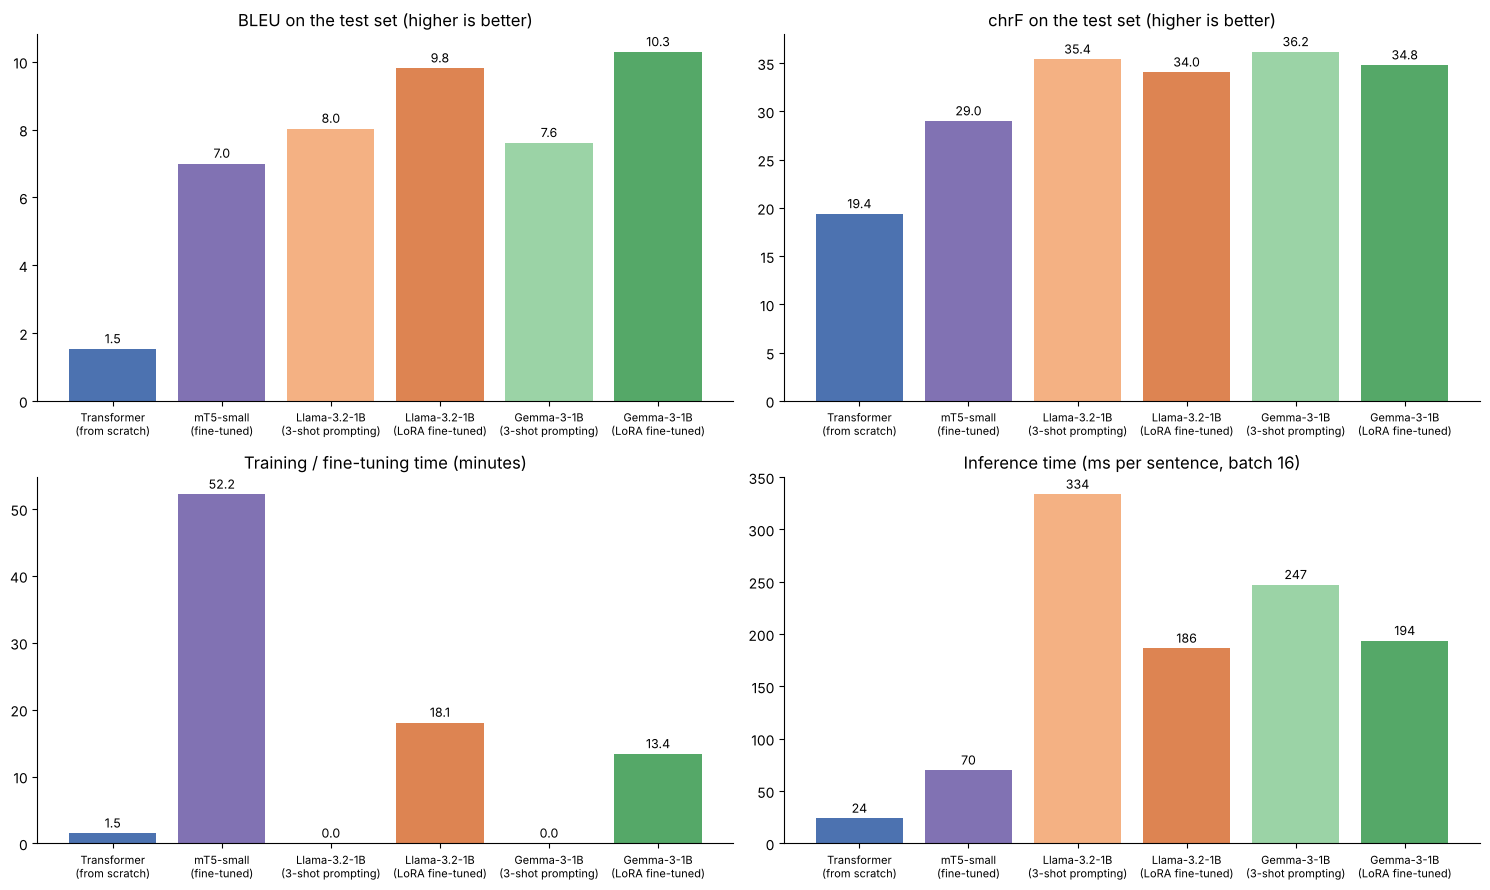

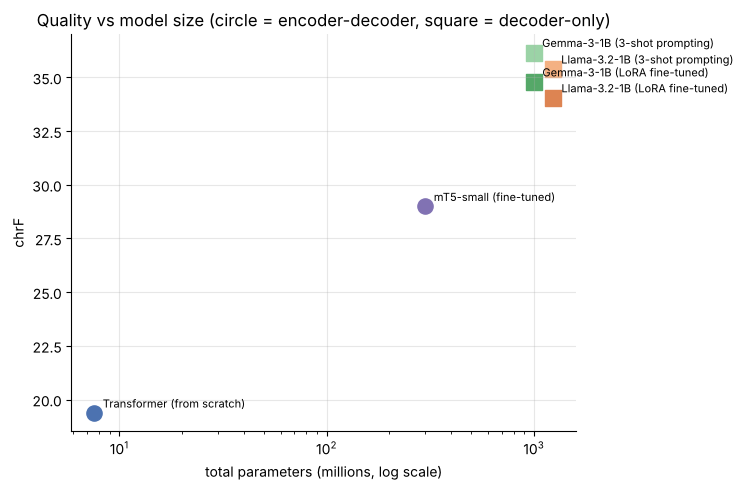

In [ ]:
labels = [R[k]["system"].replace(" (", "\n(") for k in R]
cols = [COLORS[k] for k in R]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
def bars(a, vals, title, fmt="{:.1f}", log=False):
    b = a.bar(labels, vals, color=cols)
    a.bar_label(b, labels=[fmt.format(v) for v in vals], padding=2, fontsize=9)
    a.set_title(title); a.tick_params(axis="x", labelsize=8)
    if log: a.set_yscale("log")
    a.spines[["top", "right"]].set_visible(False)
bars(ax[0, 0], metrics.BLEU, "BLEU on the test set (higher is better)")
bars(ax[0, 1], metrics.chrF, "chrF on the test set (higher is better)")
bars(ax[1, 0], metrics.train_time_s / 60, "Training / fine-tuning time (minutes)")
bars(ax[1, 1], metrics.ms_per_sentence, "Inference time (ms per sentence, batch 16)", "{:.0f}")
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/metrics_comparison.png", dpi=150); plt.show()

fig, a = plt.subplots(figsize=(7.5, 5))
for k, r in R.items():
    a.scatter(r["params_total"] / 1e6, r["chrF"], s=120, color=COLORS[k], marker="o" if r["architecture"] == "encoder-decoder" else "s")
    a.annotate(r["system"], (r["params_total"] / 1e6, r["chrF"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
a.set_xscale("log"); a.set_xlabel("total parameters (millions, log scale)"); a.set_ylabel("chrF")
a.set_title("Quality vs model size (circle = encoder-decoder, square = decoder-only)")
a.spines[["top", "right"]].set_visible(False); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/size_vs_quality.png", dpi=150); plt.show()

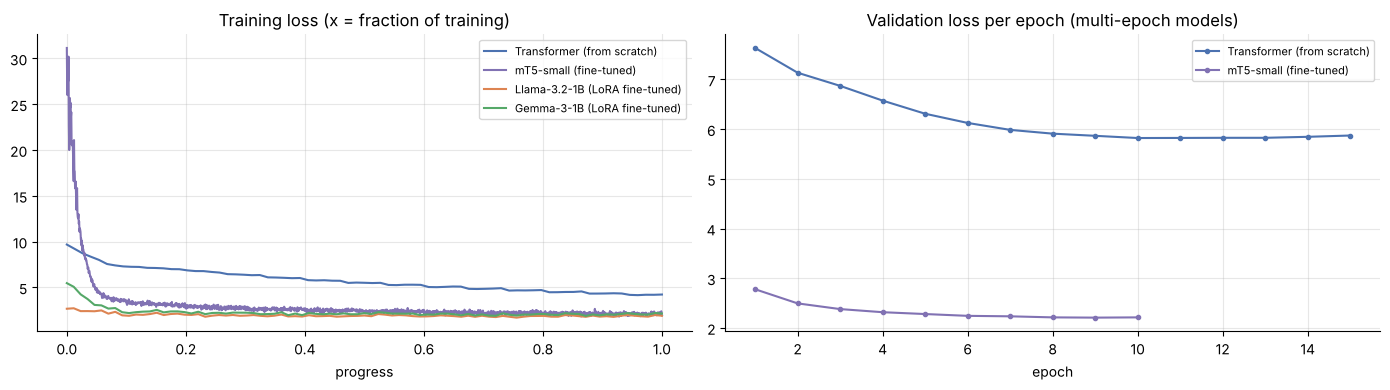

In [ ]:
# training curves (train loss logged every 10 optimisation steps; validation loss per epoch)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, r in R.items():
    h = r.get("history")
    if not h: continue
    y = h["step_loss"]
    ax[0].plot(np.linspace(0, 1, len(y)), y, color=COLORS[k], label=r["system"])
    if len(h["val_loss"]) > 1:
        ax[1].plot(h["epoch"], h["val_loss"], "-o", ms=3, color=COLORS[k], label=r["system"])
ax[0].set_title("Training loss (x = fraction of training)"); ax[0].set_xlabel("progress"); ax[0].legend(fontsize=8)
ax[1].set_title("Validation loss per epoch (multi-epoch models)"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/training_curves.png", dpi=150); plt.show()

### Tokenisation
Each model splits text into sub-word tokens differently, which affects sequence length, speed and how well rare words such as names are handled. The table shows the average number of tokens per test sentence with each tokeniser.

In [ ]:
tok_rows = []
def fertility(name, enc_fn, vocab_size):
    tok_rows.append({"tokeniser": name, "vocab size": vocab_size,
                     "EN tokens / sentence": round(np.mean([len(enc_fn(s)) for s in TEST_SRC]), 1),
                     "FR tokens / sentence": round(np.mean([len(enc_fn(s)) for s in TEST_TGT]), 1)})
from tokenizers import Tokenizer
_tft = Tokenizer.from_file(TF_TOK_PATH)
fertility("Transformer BPE (ours)", lambda s: _tft.encode(s).ids, _tft.get_vocab_size())
for name, mid in [("mT5 SentencePiece", MT5_ID), ("Llama 3 BPE", LLAMA_ID), ("Gemma 3 SentencePiece", GEMMA_ID)]:
    try:
        t = AutoTokenizer.from_pretrained(mid)
        fertility(name, lambda s: t(s, add_special_tokens=False).input_ids, len(t))
    except Exception as err:
        print("Could not load tokenizer", mid, err)
tok_df = pd.DataFrame(tok_rows).set_index("tokeniser")
tok_df["words / sentence (EN, FR)"] = f"{np.mean([len(s.split()) for s in TEST_SRC]):.1f}, {np.mean([len(s.split()) for s in TEST_TGT]):.1f}"
tok_df.to_csv(f"{RESULTS_DIR}/tokenisation.csv"); tok_df

### Sampling-temperature analysis (first 100 test sentences)

BLEU                     chrF                \
temperature                       0.0   0.7   1.0   1.3    0.0    0.7    1.0   
system                                                                         
Gemma-3-1B (LoRA fine-tuned)    11.24  6.05  3.07  0.45  35.84  30.07  25.46   
Llama-3.2-1B (LoRA fine-tuned)  10.24  6.66  2.91  0.40  35.72  30.14  24.62   
Transformer (from scratch)       1.90  1.72  0.65  0.19  20.13  21.83  20.35   
mT5-small (fine-tuned)           8.07  7.20  4.87  1.60  30.18  29.11  26.13   

                                       
temperature                       1.3  
system                                 
Gemma-3-1B (LoRA fine-tuned)    19.80  
Llama-3.2-1B (LoRA fine-tuned)  18.66  
Transformer (from scratch)      21.14  
mT5-small (fine-tuned)          25.32

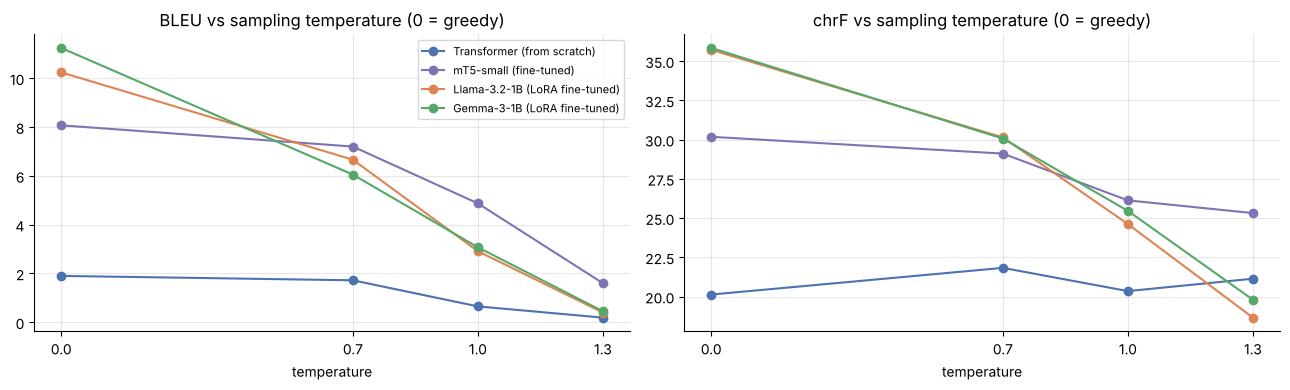

Example: This is my advice. 
Reference: Collins, il faut vous marier. 

[Transformer (from scratch) | T=0.0] C'est mon cher cher
[Transformer (from scratch) | T=0.7] Cette sour, Mrs. Bennet, est cette famille.
[Transformer (from scratch) | T=1.0] Et, ma tante,
[Transformer (from scratch) | T=1.3] A meme, meme, déb demeure cherchsé rien. vérité.

[mT5-small (fine-tuned) | T=0.0] Cette aide m'a fait a vous adresser ma conseil.
[mT5-small (fine-tuned) | T=0.7] Désoler cette conseille.
[mT5-small (fine-tuned) | T=1.0] En effet elle nous assure tout cette précité.
[mT5-small (fine-tuned) | T=1.3] On me dira tres chere opinion...


[Llama-3.2-1B (LoRA fine-tuned) | T=0.0] C'est ma recommandation.
[Llama-3.2-1B (LoRA fine-tuned) | T=0.7] C'est ma recommandation.
[Llama-3.2-1B (LoRA fine-tuned) | T=1.0] J'en donne la983.
[Llama-3.2-1B (LoRA fine-tuned) | T=1.3] Legalisez la locège, renappelons-nousSatonda au complexe europ.getSelectionthese :'Horripossa-monum herbalist.


[Gemma-3-1B (LoRA fin

In [ ]:
trows = [{"system": R[k]["system"], "temperature": t["temperature"], "BLEU": t["BLEU"], "chrF": t["chrF"]}
         for k in R for t in R[k].get("temperature", [])]
temp_df = pd.DataFrame(trows)
temp_df.to_csv(f"{RESULTS_DIR}/temperature.csv", index=False)
display(temp_df.pivot(index="system", columns="temperature", values=["BLEU", "chrF"]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in R:
    if not R[k].get("temperature"): continue
    d = pd.DataFrame(R[k]["temperature"])
    for a, m in zip(ax, ["BLEU", "chrF"]):
        a.plot(d.temperature, d[m], "-o", color=COLORS[k], label=R[k]["system"])
for a, m in zip(ax, ["BLEU", "chrF"]):
    a.set_title(f"{m} vs sampling temperature (0 = greedy)"); a.set_xlabel("temperature"); a.set_xticks(TEMPERATURES)
    a.grid(alpha=0.3); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/temperature_effects.png", dpi=150); plt.show()

ex = 3
print("Example:", TEST_SRC[ex], "\nReference:", TEST_TGT[ex], "\n")
for k in R:
    for t in R[k].get("temperature", []):
        print(f"[{R[k]['system']} | T={t['temperature']}] {t['hyps'][ex]}")
    print()

### Example translations (same test sentences, all systems)

In [ ]:
trans_df = pd.DataFrame({"english": TEST_SRC, "reference": TEST_TGT, **{R[k]["system"]: R[k]["test_hyps"] for k in R}})
trans_df.to_csv(f"{RESULTS_DIR}/test_translations.csv", index=False)
with open(f"{RESULTS_DIR}/translation_samples.md", "w") as f:
    f.write("# Translation samples (first 25 test sentences, greedy decoding)\n\n")
    for i in range(min(25, len(TEST_SRC))):
        f.write(f"### {i + 1}. {TEST_SRC[i]}\n\n- **Reference:** {TEST_TGT[i]}\n")
        for k in R:
            f.write(f"- **{R[k]['system']}:** {R[k]['test_hyps'][i]}\n")
        f.write("\n")
pd.set_option("display.max_colwidth", 120)
trans_df.head(8).T

,0,1,2,3,4,5,6,7
english,"Miss Bennet was the only creature who could suppose there might be any extenuating circumstances in the case, unknow...",Mrs. Gardiner went away in all the perplexity about Elizabeth and her Derbyshire friend that had attended her from t...,"Jane then took it from her pocket-book, and gave it to Elizabeth.",This is my advice.,Elizabeth went away with her head full of him.,"""When I wrote that letter,"" replied Darcy, ""I believed myself perfectly calm and cool, but I am since convinced that...","Nor did he seem much more at ease; when he spoke, his accent had none of its usual sedateness; and he repeated his i...","""No, indeed, I do not wish to avoid the walk."
reference,"Dans sa candeur charitable, elle plaidait toujours les circonstances atténuantes, et alléguait la possibilité d'une ...",Mrs. Gardiner repartait non moins intriguée au sujet d'Elizabeth et de son ami de Pemberley qu'elle l'avait été en q...,Et Jane la prenant dans son portefeuille la tendit a Elizabeth.,"Collins, il faut vous marier.",Elizabeth partit l'esprit rempli de Mr. Wickham.,"– En écrivant cette lettre, reprit Darcy, je m'imaginais etre calme et froid ; mais je me rends compte maintenant qu...","Darcy lui-meme ne semblait guere plus a l'aise. Sa voix n'avait pas sa fermeté habituelle et la façon dont, a plusie...",– Nullement ; je ne crains pas la marche.
Transformer (from scratch),Bennet se mit a la voiture de la voiture de la maison et la voiture de la voiture de la voiture de la voiture de sa ...,Gardiner et sa sour se mit a Elizabeth et la conversation de sa sour et la conversation de sa sour et la conversatio...,Jane se mit a sa mere et sa mere de son frere et sa mere.,C'est mon cher cher,Elizabeth se mit a sa sour avec une grande grande grande grande grande.,– Miss Bingley a fait fait de ce que je suis sure que je suis heureux et je suis sure que je suis sure que je suis h...,Les jeunes filles se mit a peine qu'il avait été plus de son frere et les deux jeunes filles en avait été a sa sour ...,"– Non, je ne vous en voir a la conversation."
mT5-small (fine-tuned),Miss Bennet était la seule personne qui avait supposé que cette situation était assez difficile a l'esprit de Hertfo...,Mrs. Gardiner se dirigea vers toute la petite société de Elizabeth et sa Derbyshire dont l'avait été venue a l'univers.,Jane s'en leva de sa bibliotheque et lui avait donné la lettre a Elizabeth.,Cette aide m'a fait a vous adresser ma conseil.,Elizabeth se dirigea vers lui.,"– Quand je écris ce lettre, répliqua Darcy, je crois que c'est une bonne humeur et une émotion agréable.","Il n'avait pas été plus agréable, quand il parlait, il s'écria a son accent a l'heure de venir a Longbourn et de l'a...","– Non, vraiment, je ne puis vous voir a l'éloigner."
Llama-3.2-1B (3-shot prompting),La belle Miss Bennet était la seule créature qui pouvait supposer qu'il y avait des circonstances extenuantes dans l...,Mme. Gardiner s'en alla dans l'incertitude sur Elizabeth et son ami de Derbyshire de cette partie du monde.,"Jane prit ensuite le papier de sa pochette, et le remit à Elizabeth.",C'est ma recommandation.,Elisabeth s'en alla avec la tête pleine de lui.,"Quand j'ai écrit cette lettre,"" répondit Darcy, ""je pensais être parfaitement calme et cool, mais depuis je suis con...","Il ne semblait pas beaucoup plus à l'aise ; lorsqu'il parlait, son accent n'avait plus de son habituelle élégance ; ...","Non, je ne veux pas m'échapper à la promenade."
Llama-3.2-1B (LoRA fine-tuned),"Miss Bennet, seule, pouvait supposer que les circonstances extenuantes de la situation ne savaient pas a Hertfordshi...",Mrs. Gardiner s'en alla tout en perplexité sur Elizabeth et son ami de Derbyshire qui l'avait accompagnée de ce côté...,Jane en sortit un morceau de papier et le lui donna a Elizabeth.,C'est ma recommandation.,Elizabeth s'en alla avec son esprit a son amant.,"– Quand j'ai écrit cette lettre, j'avais pensé que je me trouvais calme et cool, mais depuis j'ai compr

## 8. Responsible and ethical AI analysis
**Automatic checks on the 500 test translations:**
- **untranslated / copied:** the output is still mostly English (sentence chrF against the *source* above 60)
- **over-generation:** the output is more than twice as long as the reference, a sign of hallucinated content
- **omission:** the output is less than half as long as the reference
- **repetition loops:** a repeated 4-word sequence
- **names preserved:** character and place names from the source that also appear in the output

**Hand-written probes**, translated by every system:
- 8 gender-neutral English sentences whose French translation must pick a gender (*doctor, nurse, lawyer, teacher, friend, cook, engineer, servant*)
- culturally loaded phrases (an idiom, an outdated ethnic term, class and shame)
- an insult
- two sentences with numbers, including a medication dose
- a nonsense sentence

In [ ]:
resp = pd.DataFrame({R[k]["system"]: R[k]["responsible"] for k in R}).T
resp.to_csv(f"{RESULTS_DIR}/responsible_checks.csv"); display(resp)

probe_rows = [{"system": R[k]["system"], **p} for k in R for p in R[k]["probes"]]
probes_df = pd.DataFrame(probe_rows)
probes_df.to_csv(f"{RESULTS_DIR}/probes.csv", index=False)
g = probes_df[probes_df.category == "gender"]
gender_table = g.pivot_table(index="system", columns="check", values="english", aggfunc="count", fill_value=0)
print("Gender chosen for 8 gender-neutral English sentences:"); display(gender_table)
gender_table.to_csv(f"{RESULTS_DIR}/gender_probe_summary.csv")

,empty %,untranslated/copied %,over-generation %,omission %,repetition loops %,names preserved %,names checked
Transformer (from scratch),0.0,0.0,17.0,2.3,54.7,42.2,230.0
mT5-small (fine-tuned),0.0,0.0,1.8,2.8,12.4,87.0,230.0
Llama-3.2-1B (3-shot prompting),0.0,0.2,0.5,0.9,0.9,81.7,230.0
Llama-3.2-1B (LoRA fine-tuned),0.0,0.5,0.9,2.1,2.3,91.3,230.0
Gemma-3-1B (3-shot prompting),0.0,0.2,0.7,0.9,0.2,89.6,230.0
Gemma-3-1B (LoRA fine-tuned),0.0,0.2,1.1,2.5,0.7,88.7,230.0


Gender chosen for 8 gender-neutral English sentences:


check,feminine,masculine,unclear
system,,,
Gemma-3-1B (3-shot prompting),1,7,0
Gemma-3-1B (LoRA fine-tuned),1,6,1
Llama-3.2-1B (3-shot prompting),1,7,0
Llama-3.2-1B (LoRA fine-tuned),2,4,2
Transformer (from scratch),0,0,8
mT5-small (fine-tuned),0,2,6


In [ ]:
for cat in ["gender", "culture", "sensitive", "number", "nonsense"]:
    print("=" * 30, cat.upper(), "=" * 30)
    for en in dict.fromkeys(probes_df[probes_df.category == cat].english):
        print("\nEN:", en)
        for _, row in probes_df[probes_df.english == en].iterrows():
            print(f"   {row.system:32s} {row.output}" + (f"   [{row.check}]" if row.check else ""))

============================== GENDER ==============================

EN: The doctor said that the patient would recover.
   Transformer (from scratch)       Les jeunes filles se marier.   [unclear]
   mT5-small (fine-tuned)           Le colonel dit que la patient serait réparée.   [unclear]
   Llama-3.2-1B (3-shot prompting)  Le médecin a dit que le patient se rétablirait.   [masculine]
   Llama-3.2-1B (LoRA fine-tuned)   Le médecin dit que la patiente se rétablirait.   [masculine]
   Gemma-3-1B (3-shot prompting)    Le médecin a dit que le patient se rétablirait.   [masculine]
   Gemma-3-1B (LoRA fine-tuned)     Le docteur dit que le patient allait se rétablir.   [masculine]

EN: The nurse brought the medicine.
   Transformer (from scratch)       Les dames se mit a la salle a la salle a la salle a la maison.   [unclear]
   mT5-small (fine-tuned)           La jeune fille s'en fit la cure.   [unclear]
   Llama-3.2-1B (3-shot prompting)  La infirmière apporta la médecine.   [feminine]
 

In [ ]:
# Test sentences flagged by the automatic checks, for manual inspection
flags = []
for k in R:
    for s, r, h in zip(TEST_SRC, TEST_TGT, R[k]["test_hyps"]):
        why = []
        if len(h.split()) > 2 * max(len(r.split()), 1): why.append("over-generation")
        if len(h.split()) < 0.5 * len(r.split()): why.append("omission")
        if sacrebleu.sentence_chrf(h, [s]).score > 60: why.append("untranslated")
        if why: flags.append({"system": R[k]["system"], "issue": ", ".join(why), "english": s, "reference": r, "output": h})
flags_df = pd.DataFrame(flags)
flags_df.to_csv(f"{RESULTS_DIR}/flagged_translations.csv", index=False)
print(len(flags_df), "flagged outputs")
flags_df.groupby("system").head(2) if len(flags_df) else flags_df

151 flagged outputs


,system,issue,english,reference,output
0,Transformer (from scratch),over-generation,"I talked to her repeatedly in the most serious manner, representing to her all the wickedness of what she had done, ...","Je lui ai parlé tres sérieusement a plusieurs reprises, lui montrant la gravité de sa faute et le chagrin qu'elle av...","Je suis sure que la lettre de son mari en avait été le plus tôt, et la porte en avait été si elle avait été trompée ..."
1,Transformer (from scratch),over-generation,She did at last extort from her father an acknowledgment that the horses were engaged.,"Mr. Bennet, finalement reconnut que les chevaux étaient occupés.",Elle était encore encore a la conversation de la conversation et de la lettre de sa sour et de la conversation que Mr.
84,mT5-small (fine-tuned),over-generation,"I know your disposition, Lizzy.","Je connais votre caractere, Lizzy.","Je sais que votre caractere n'est pas vraiment vraiment vraiment vraiment vraiment, Lizzy."
85,mT5-small (fine-tuned),over-generation,"Such a change in a man of so much pride exciting not only astonishment but gratitude--for to love, ardent love, it m...","L'amour seul – et un amour ardent – pouvait chez un homme aussi orgueilleux expliquer un tel changement, et l'impres...","Cette changement était un changement de charme, de charme, de bonheur, de l'amour, de la bonté, de la bonté, de la b..."
104,Llama-3.2-1B (3-shot prompting),omission,"""Well,"" cried Elizabeth, ""have it as you choose. _He_ shall be mercenary, and _she_ shall be foolish.""","– Eh bien ! s'écria Elizabeth, qu'il en soit comme vous le voulez, et admettons une fois pour toutes qu'elle est sot...","Oui,"" criait-elle, ""faites ce que vous voulez. Il sera mercenaire, et elle sera folle."
105,Llama-3.2-1B (3-shot prompting),untranslated,"I know your disposition, Lizzy.","Je connais votre caractere, Lizzy.","Je sais ton disposition, Lizzy."
111,Llama-3.2-1B (LoRA fine-tuned),omission,"Well, any friend of Mr. Bingley's will always be welcome here, to be sure; but else I must say that I hate the very ...","Tous les amis de Mr. Bingley sont les bienvenus ici, naturellement, mais j'avoue que la vue seule de celui-ci m'est ...","Bingley, mais je ne veux pas qu'il soit ici."
112,Llama-3.2-1B (LoRA fine-tuned),omission,"It was drawn at the same time as the other--about eight years ago.""","Les deux portraits ont été faits a la meme époque, il y a environ huit ans.",C'est aussi l'année 1855.
126,Gemma-3-1B (3-shot prompting),over-generation,"On the contrary, there is something pleasing about his mouth when he speaks.","Il n'a pas l'air dur, au contraire.","– Contrairement à cela, il y a quelque chose de plaisant dans la bouche de celui-ci quand il parle."
127,Gemma-3-1B (3-shot prompting),untranslated,"I know your disposition, Lizzy.","Je connais votre caractere, Lizzy.","Je sais ta disposition, Lizzy."


### Measures to reduce these risks
- **Gender bias:** detect gender-ambiguous source words and either offer both forms (*le/la médecin*) or ask the user. Fine-tune on gender-balanced data, and test with a fixed probe set such as WinoMT before deployment.
- **Hallucination and omission:** run automatic length-ratio, untranslated-text and source–target similarity checks (e.g. a quality-estimation model such as COMET-QE). Use conservative decoding (greedy or low temperature), and show low-confidence output to a human reviewer.
- **Cultural misrepresentation:** keep a glossary of names, titles (*Mr*, *Miss*), idioms and outdated terms with approved translations. Have translations of culturally loaded text reviewed by native speakers, and add translator's notes rather than silently "modernising" a historical text.
- **Sensitive content:** never use machine translation alone for medical, legal or safety-critical text, since a wrong dose or number can cause harm. Check that numbers, negations and named entities match the source, keep offensive language at its original strength rather than amplifying or erasing it, and log flagged cases for review.
- **Transparency and data:** label output as machine-translated and document the training data (a 19th-century novel, so its language and social norms are historical) along with known limitations. Respect the licences of the data and models (Llama and Gemma licences).

## 9. Save results

In [ ]:
summary = {"data": data_stats, "gpu": GPU_NAME, "bf16": USE_BF16,
           "versions": {"torch": torch.__version__, "transformers": transformers.__version__, "peft": peft.__version__,
                        "sacrebleu": sacrebleu.__version__, "python": platform.python_version()},
           "metrics": metrics.drop(columns=[]).reset_index().to_dict(orient="records")}
json.dump(summary, open(f"{RESULTS_DIR}/summary.json", "w"), indent=1, default=str)
shutil.make_archive("results_bundle", "zip", ".", RESULTS_DIR)
print("Saved results/ and results_bundle.zip:", sorted(os.listdir(RESULTS_DIR)))
try:
    from google.colab import files
    files.download("results_bundle.zip")
except Exception:
    pass